In [1]:
# studying ridge key points

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# as we increase lambda, the coefficients decreases and tries to reach zero but not zero

In [5]:
from sklearn.datasets import load_diabetes

In [15]:
data = load_diabetes()

In [16]:
df = pd.DataFrame(data = data.data, columns= data.feature_names)
df['targ'] = data.target

In [17]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,targ
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [25]:
df.iloc[:, :-1]

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [9]:
from sklearn.model_selection import train_test_split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :-1], df.iloc[:, -1], test_size= 0.2, random_state= 42)

In [27]:
from sklearn.linear_model import Ridge

In [30]:
alphas = [0, 1, 10, 100]
coefs = []
for i in alphas:
    rd = Ridge(alpha= i)
    rd.fit(X_train, y_train)
    coefs.append(rd.coef_)

Text(0.5, 1.0, '100')

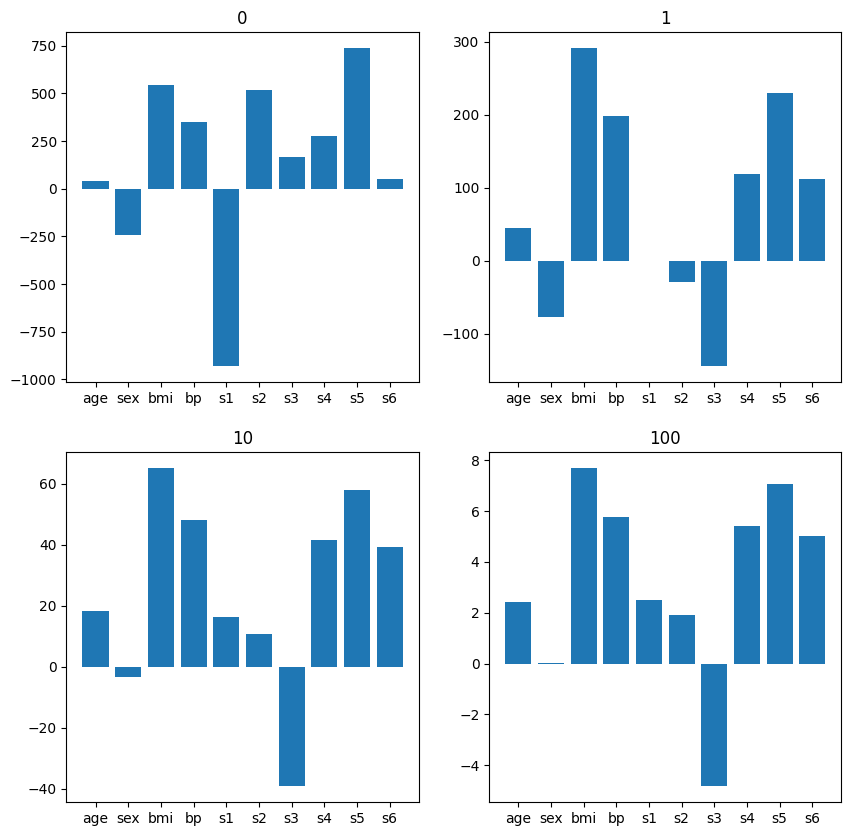

In [45]:
fig, ax = plt.subplots(2, 2, figsize = (10, 10))

ax[0, 0].bar(data.feature_names, coefs[0])
ax[0, 0].set_title(f'{alphas[0]}')

ax[0, 1].bar(data.feature_names, coefs[1])
ax[0, 1].set_title(f'{alphas[1]}')

ax[1, 0].bar(data.feature_names, coefs[2])
ax[1, 0].set_title(f'{alphas[2]}')

ax[1, 1].bar(data.feature_names, coefs[3])
ax[1, 1].set_title(f'{alphas[3]}')

In [46]:
# coefficients with higher values will decrease faster

In [72]:
alphas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 5]
coefs = []

for i in alphas:
    rd = Ridge(alpha= i)
    rd.fit(X_train, y_train)
    coefs.append(rd.coef_)

In [73]:
coeff_arr = np.array(coefs)

In [74]:
df = pd.DataFrame(columns= data.feature_names, data = coeff_arr)

In [75]:
df['alpha'] = alphas
df.set_index('alpha', inplace= True)
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
alpha,,,,,,,,,,
0.0000,37.904021,-241.964362,542.428759,347.703844,-931.488846,518.062277,163.419983,275.317902,736.198859,48.670657
0.0001,37.968967,-241.900460,542.593504,347.604088,-919.863924,508.995920,158.213776,273.689919,731.714305,48.786920
0.0010,38.483505,-241.351795,543.835179,346.782831,-827.701995,437.173749,116.949753,260.759264,696.129223,49.743447
0.0100,40.693422,-237.008020,546.161792,341.809317,-430.146300,129.902301,-60.460817,203.990842,541.098025,55.482553
0.1000,42.855670,-205.494319,505.089033,317.093205,-108.500262,-86.236733,-190.363180,151.707086,392.289319,79.908177
1.0000,45.367377,-76.666086,291.338832,198.995817,-0.530310,-28.577050,-144.511905,119.260066,230.221608,112.149830
5.0000,28.308758,-10.925672,112.562976,82.099040,21.303402,11.462687,-65.220227,65.574952,97.418692,63.099633


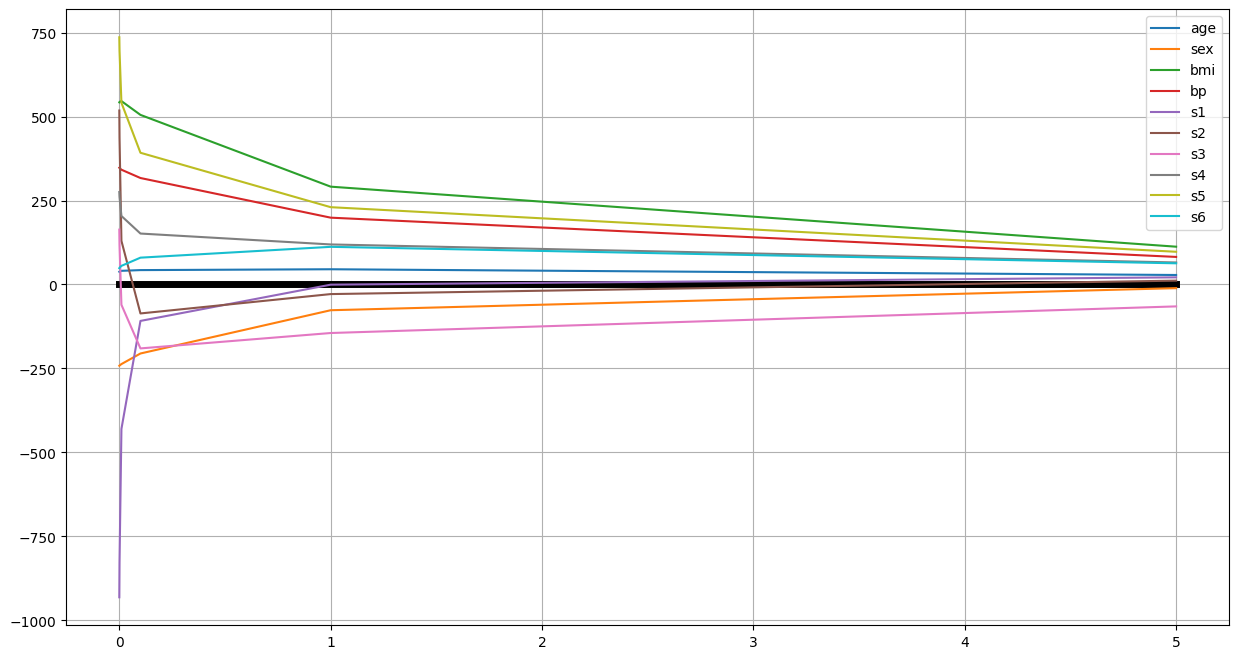

In [76]:
plt.figure(figsize=(15, 8))
plt.plot(df.index, np.zeros(len(alphas)), color = 'black', linewidth = 5)
for col in df.columns:
    plt.plot(df.index, df[col], label = col)
plt.legend()
plt.grid(True)
plt.show()